# 08 — Tarefas binárias com pesos de sexo × idade e sem a feature idade

Refaz o notebook 06 (TEA × Controle no ABIDE I; TDAH × Controle no ADHD-200; fenótipo, conectividade e fusões) com a
abordagem decidida no notebook 07:

- **Pesos de sexo × idade** (`src/weighting.py`) dentro de cada tarefa: casos e controles passam a ter a mesma
  distribuição de sexo e idade. Os pesos entram no treino **e** na avaliação.
- **Idade fora das features.** Ela não tem sinal diagnóstico; só marcava o recrutamento.
- Sexo continua fora das features (como no 06).

Isso também importa para a conectividade: ela muda com a idade e difere entre sexos. Sem os pesos, um classificador de
conectividade pode separar casos de controles só porque um grupo é mais velho ou tem mais meninos.

Mesma validação do 06 (`GroupKFold` por instituição, 5 dobras, sementes 0–2), para comparar número a número.

| Seção | O que compara |
|---|---|
| 1 | Equilíbrio de sexo e idade entre casos e controles, antes e depois dos pesos |
| 2 | Só fenótipo, 2 × 2: com/sem idade × com/sem pesos (10 sementes) — separa o efeito de cada mudança |
| 3 | Os 16 modelos do notebook 06 na nova configuração, comparados ao 06 |

In [1]:
import sys
import warnings
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from connectivity import standardize_by_group
from evaluation import metrics_binary, repeated_group_cv
from fusion import make_fusion_models
from harmonize import INSTITUTION, load_adhd200
from weighting import covariate_weights, effective_n, weighted_smd

warnings.filterwarnings("ignore")
FIG = ROOT / "results" / "figures"
sns.set_theme(style="whitegrid", context="notebook")
SEEDS = range(3)
CONJUNTOS = ["Fenótipo", "Conectividade", "Fusão precoce", "Fusão tardia"]
MODELOS = ["Regressão logística", "Árvore de decisão", "Random Forest", "XGBoost"]

npz = np.load(ROOT / "data" / "processed" / "connectivity_aal.npz", allow_pickle=True)
FC = pd.DataFrame(npz["X"], index=npz["subject_id"])

coorte = pd.read_csv(ROOT / "data" / "interim" / "cohort_7_21.csv").set_index("subject_id")
abide = coorte[(coorte.release == "ABIDE_I") & coorte.index.isin(FC.index)]
adhd = load_adhd200()
adhd = adhd[adhd.diagnosis.notna() & adhd.age.between(7, 21) & adhd.subject_id.isin(FC.index)].copy()
adhd["institution"] = adhd.site.replace(INSTITUTION)
adhd = adhd.set_index("subject_id")

# Os pesos precisam do sexo: quem não tem fica de fora (comparar com os n do notebook 06).
TAREFAS = {}
for t, d, pos in [("TEA × Controle (ABIDE I)", abide, "TEA"), ("TDAH × Controle (ADHD-200)", adhd, "TDAH")]:
    sem_sexo = d.sex.isna().sum()
    d = d[d.sex.notna()]
    TAREFAS[t] = (d, pos, covariate_weights(d).to_numpy())
    print(f"{t}: {len(d)} sujeitos ({(d.diagnosis == pos).sum()} {pos}), {d.institution.nunique()} instituições; "
          f"{sem_sexo} sem sexo excluídos")

def fenotipo(d, idade=False):
    F = pd.DataFrame({"qi_total": d.fiq, "qi_verbal": d.viq, "qi_execucao": d.piq, "discrep_viq_piq": d.viq - d.piq})
    if idade:
        F.insert(0, "idade", d.age)
    return F

TEA × Controle (ABIDE I): 732 sujeitos (345 TEA), 17 instituições; 0 sem sexo excluídos
TDAH × Controle (ADHD-200): 852 sujeitos (322 TDAH), 7 instituições; 1 sem sexo excluídos


## 1. Sexo e idade entre casos e controles, antes e depois dos pesos

In [2]:
linhas = []
for t, (d, pos, w) in TAREFAS.items():
    dd = d.assign(sexo_m=(d.sex == "M").astype(float))
    a, b = f"{pos} ({d.dataset.iloc[0]})", f"Controle ({d.dataset.iloc[0]})"
    for col, nome in [("age", "idade"), ("sexo_m", "sexo")]:
        linhas.append({"tarefa": t, "variável": nome, "SMD sem pesos": weighted_smd(dd, col, a, b),
                       "SMD com pesos": weighted_smd(dd, col, a, b, w)})
    caso = (d.diagnosis == pos).to_numpy()
    print(f"{t}: n efetivo {effective_n(w[caso]):.0f} de {caso.sum()} casos, "
          f"{effective_n(w[~caso]):.0f} de {(~caso).sum()} controles")
pd.DataFrame(linhas).round(2)

TEA × Controle (ABIDE I): n efetivo 337 de 345 casos, 382 de 387 controles
TDAH × Controle (ADHD-200): n efetivo 278 de 322 casos, 502 de 530 controles


,tarefa,variável,SMD sem pesos,SMD com pesos
0,TEA × Controle (ABIDE I),idade,0.00,0.00
1,TEA × Controle (ABIDE I),sexo,0.22,0.01
2,TDAH × Controle (ADHD-200),idade,-0.14,-0.07
3,TDAH × Controle (ADHD-200),sexo,0.58,0.05


## 2. Só fenótipo: qual mudança faz diferença?
Quatro combinações, 10 sementes, regressão logística e árvore (os modelos mais estáveis com poucas features).
Os pesos, quando usados, entram no treino e no teste.

In [3]:
from fusion import make_fusion_models as _mf
linhas = []
for t, (d, pos, w) in TAREFAS.items():
    y = (d.diagnosis == pos).astype(int).to_numpy()
    g = d.institution.to_numpy()
    for idade in [True, False]:
        F = fenotipo(d, idade)
        for usar_peso in [False, True]:
            fw = w if usar_peso else None
            for modelo in ["Regressão logística", "Árvore de decisão"]:
                est = _mf(F.shape[1], 0)[(modelo, "Fenótipo")]
                r, _ = repeated_group_cv(est, F.to_numpy(), y, g, seeds=range(10), fit_weight=fw, eval_weight=fw,
                                         metric_fn=partial(metrics_binary, nomes=("Controle", "caso")))
                linhas.append({"tarefa": t, "modelo": modelo, "features": "com idade" if idade else "sem idade",
                               "pesos sexo × idade": "sim" if usar_peso else "não",
                               "acc_bal": r.acc_balanceada.mean(), "dp": r.acc_balanceada.std(), "auc": r.auc.mean()})
grade = pd.DataFrame(linhas)
grade.pivot_table(index=["tarefa", "modelo"], columns=["pesos sexo × idade", "features"], values="acc_bal").round(3)

pesos sexo × idade                                   não                 sim  \
features                                       com idade sem idade com idade   
tarefa                     modelo                                              
TDAH × Controle (ADHD-200) Regressão logística     0.577     0.595     0.584   
                           Árvore de decisão       0.554     0.565     0.540   
TEA × Controle (ABIDE I)   Regressão logística     0.596     0.598     0.600   
                           Árvore de decisão       0.567     0.576     0.579   

pesos sexo × idade                                        
features                                       sem idade  
tarefa                     modelo                         
TDAH × Controle (ADHD-200) Regressão logística     0.603  
                           Árvore de decisão       0.550  
TEA × Controle (ABIDE I)   Regressão logística     0.601  
                           Árvore de decisão       0.588

## 3. Os 16 modelos na nova configuração (pesos, sem idade)

In [4]:
res = {}
for t, (d, pos, w) in TAREFAS.items():
    F = fenotipo(d)
    C = standardize_by_group(FC.loc[d.index].to_numpy(), d.institution.to_numpy())
    X = np.hstack([F.to_numpy(), C])
    y = (d.diagnosis == pos).astype(int).to_numpy()
    g = d.institution.to_numpy()
    for (modelo, conj), est in make_fusion_models(F.shape[1], C.shape[1]).items():
        r, _ = repeated_group_cv(est, X, y, g, seeds=SEEDS, fit_weight=w, eval_weight=w,
                                 metric_fn=partial(metrics_binary, nomes=("Controle", "caso")))
        res[(t, modelo, conj)] = r
    print("ok:", t)

tab = pd.DataFrame({k: r.drop(columns="semente").mean() for k, r in res.items()}).T
tab.index.names = ["tarefa", "modelo", "conjunto"]
for t in TAREFAS:
    print(f"\n=== {t}: acurácia balanceada (AUC) ===")
    sub = tab.loc[t]
    acc = sub["acc_balanceada"].unstack("conjunto").loc[MODELOS, CONJUNTOS]
    auc = sub["auc"].unstack("conjunto").loc[MODELOS, CONJUNTOS]
    print((acc.round(3).astype(str) + " (" + auc.round(2).astype(str) + ")").to_string())

ok: TEA × Controle (ABIDE I)


ok: TDAH × Controle (ADHD-200)

=== TEA × Controle (ABIDE I): acurácia balanceada (AUC) ===
conjunto                 Fenótipo Conectividade Fusão precoce  Fusão tardia
modelo                                                                     
Regressão logística  0.601 (0.63)  0.643 (0.69)  0.638 (0.69)  0.666 (0.71)
Árvore de decisão    0.587 (0.61)  0.564 (0.57)  0.582 (0.61)  0.598 (0.62)
Random Forest        0.596 (0.62)  0.623 (0.68)  0.619 (0.68)  0.626 (0.67)
XGBoost              0.583 (0.62)  0.638 (0.69)  0.641 (0.71)   0.653 (0.7)

=== TDAH × Controle (ADHD-200): acurácia balanceada (AUC) ===
conjunto                 Fenótipo Conectividade Fusão precoce  Fusão tardia
modelo                                                                     
Regressão logística  0.602 (0.64)  0.489 (0.47)  0.493 (0.48)  0.514 (0.52)
Árvore de decisão    0.552 (0.57)   0.504 (0.5)  0.528 (0.53)  0.533 (0.55)
Random Forest        0.565 (0.58)   0.49 (0.46)  0.495 (0.48)  0.566 (0.57)
XGBoost  

### Comparação com o notebook 06
Valores do 06 (sem pesos, idade como feature, mesmas sementes). Diferença = 08 − 06.

conjunto                                        Fenótipo  Conectividade  \
tarefa                     modelo                                         
TDAH × Controle (ADHD-200) Random Forest           0.041         -0.003   
                           Regressão logística     0.028         -0.013   
                           XGBoost                 0.026         -0.026   
                           Árvore de decisão       0.008          0.005   
TEA × Controle (ABIDE I)   Random Forest           0.016          0.013   
                           Regressão logística     0.007          0.002   
                           XGBoost                 0.022         -0.001   
                           Árvore de decisão       0.014          0.012   

conjunto                                        Fusão precoce  Fusão tardia  
tarefa                     modelo                                            
TDAH × Controle (ADHD-200) Random Forest               -0.012         0.045  
                           Regressão logística         -0.009        -0.006  
                           XGBoost                      0.008         0.018  
                           Árvore de decisão           -0.003         0.027  
TEA × Controle (ABIDE I)   Random Forest               -0.004         0.016  
                           Regressão logística         -0.008         0.004  
                           XGBoost                     -0.007         0.009  
                           Árvore de decisão           -0.003         0.013

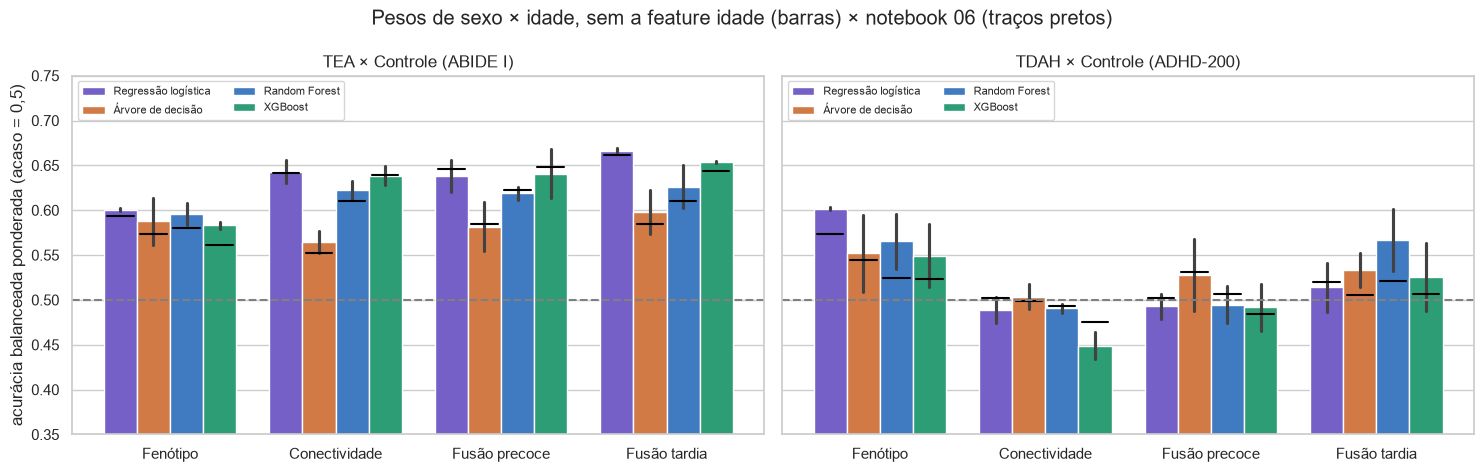

In [5]:
NB06 = {
    "TEA × Controle (ABIDE I)": {
        "Fenótipo": [.594, .573, .580, .561], "Conectividade": [.641, .552, .610, .639],
        "Fusão precoce": [.646, .585, .623, .648], "Fusão tardia": [.662, .585, .610, .644]},
    "TDAH × Controle (ADHD-200)": {
        "Fenótipo": [.574, .544, .524, .523], "Conectividade": [.502, .499, .493, .475],
        "Fusão precoce": [.502, .531, .507, .484], "Fusão tardia": [.520, .506, .521, .507]},
}
comp = []
for t in TAREFAS:
    for c in CONJUNTOS:
        for i, m in enumerate(MODELOS):
            novo = res[(t, m, c)].acc_balanceada.mean()
            comp.append({"tarefa": t, "modelo": m, "conjunto": c, "06": NB06[t][c][i], "08": novo,
                         "diferença": novo - NB06[t][c][i]})
comp = pd.DataFrame(comp)
display(comp.pivot_table(index=["tarefa", "modelo"], columns="conjunto", values="diferença")[CONJUNTOS].round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
cores = {"Regressão logística": "#6a4fd8", "Árvore de decisão": "#e8742f", "Random Forest": "#2a78d6", "XGBoost": "#1baf7a"}
longo = pd.concat([r.assign(tarefa=k[0], modelo=k[1], conjunto=k[2]) for k, r in res.items()])
for ax, t in zip(axes, TAREFAS):
    sns.barplot(data=longo[longo.tarefa == t], x="conjunto", y="acc_balanceada", hue="modelo", order=CONJUNTOS,
                hue_order=MODELOS, palette=cores, errorbar="sd", ax=ax)
    ref = comp[comp.tarefa == t]
    for i, c in enumerate(CONJUNTOS):
        for j, m in enumerate(MODELOS):
            v = ref[(ref.conjunto == c) & (ref.modelo == m)]["06"].iloc[0]
            x = i - 0.4 + 0.1 + j * 0.2
            ax.plot([x - 0.08, x + 0.08], [v, v], c="black", lw=1.5)
    ax.axhline(0.5, ls="--", c="gray"); ax.set_ylim(0.35, 0.75); ax.set_title(t); ax.set_xlabel("")
    ax.legend(fontsize=8, loc="upper left", ncol=2)
axes[0].set_ylabel("acurácia balanceada ponderada (acaso = 0,5)")
fig.suptitle("Pesos de sexo × idade, sem a feature idade (barras) × notebook 06 (traços pretos)")
plt.tight_layout(); plt.savefig(FIG / "08_binarias_pesos.png", dpi=150)

## 4. Leitura dos resultados

**Equilíbrio.** No ABIDE I, TEA e controles já tinham a mesma idade (SMD 0,00), mas não o mesmo sexo (0,22). No ADHD-200
o desequilíbrio de sexo era grande (0,58: mais meninos no TDAH). Com os pesos, tudo fica abaixo de 0,07, e quase
nenhuma amostra se perde (n efetivo: 337/345 TEA, 382/387 controles; 278/322 TDAH, 502/530 controles).

**Nenhum resultado caiu; vários subiram um pouco.** Comparado ao notebook 06 (sem pesos, idade como feature):
- **TEA × Controle:** fusão tardia com regressão logística **0,67** (AUC 0,71; era 0,66), ainda o melhor do projeto.
  XGBoost com fusão tardia 0,65. A conectividade sozinha fica igual (logística 0,64), coerente com a idade já equilibrada no ABIDE I.
- **TDAH × Controle:** só fenótipo, regressão logística **0,60** (AUC 0,64; era 0,57). A grade da seção 2 mostra que
  o ganho vem de tirar a idade e de equilibrar o sexo: o QI fica mais "limpo" sem a idade (o QI já é normatizado por idade).
  A conectividade continua no acaso (0,45–0,50), e somá-la ao fenótipo piora.

**Comitês × árvore.** Com sinal (TEA), RF e XGBoost superam a árvore em até +0,07 (XGBoost com conectividade), mas a
regressão logística regularizada empata ou vence. Sem sinal (TDAH), ninguém se destaca da regressão logística no fenótipo.

**Conclusão:** os resultados principais não dependiam de atalhos de sexo e idade. Esta configuração (pesos de sexo × idade,
sem a feature idade) passa a ser a de referência para as tarefas binárias; o notebook 06 fica como comparação.